In [1]:
import pandas as pd
from tabulate import tabulate
import re
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv('dataset_grupo_08.csv')

In [3]:
df2= pd.get_dummies(df, columns=['target_class'], prefix='target', drop_first=False, dtype=int)
df2.head()

,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,...,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_DI,target_HY,target_N
0,Middle,Male,Obese,Never,44,0.482758,35.70,5.398540,250.000000,5.300000,...,Primary,Employed,116.000000,9.42,1.015947,160.000000,177.0,0,1,0
1,Mature,Male,Obese,Former,49,0.540230,34.97,6.500000,224.684501,7.060728,...,Secondary,Unemployed,134.331495,9.42,1.245353,111.000000,80.0,0,0,1
2,Young,Male,Underweight,Never,4,0.022989,17.64,6.000000,228.130653,7.080402,...,Tertiary,Employed,133.010050,9.42,1.156861,130.259429,126.0,0,0,1
3,Middle,Male,Underweight,Current,40,0.436781,17.30,5.421429,299.000000,9.500000,...,Primary,Employed,124.000000,9.42,1.030313,176.000000,190.0,0,1,0
4,Middle,Female,Normal,Current,27,0.287356,24.80,5.374373,277.000000,8.500000,...,Tertiary,Employed,96.000000,9.42,1.461792,143.000000,175.0,0,0,1


In [4]:
print(
    f"""
    Head Dataset

    {tabulate(
        df.head(10),
        headers="keys",
        tablefmt="grid",
        showindex=False
    )}
    """
)

print(f"""
Tail Dataset

{tabulate(
    df.tail(10),
    headers="keys",
    tablefmt="grid",
    showindex=False
)}
""")


    Head Dataset

    +-------------+----------+-------------+-----------+-------+------------------+-------+---------------+---------------+---------------+-----------------+---------------------+------------------+----------------+-----------------------+------------------------+------------------+---------------------+-------------+----------------------+---------------+----------------+------------------+---------------+--------------+---------+---------+-------------------+---------------------+------------------+--------------------+----------------+-------------------+---------------------+----------------+
| age_level   | gender   | bmi_level   | smoking   |   age |   age_normalized |   bmi |   HbA1c_level |   cholesterol |   sleep_hours |   triglycerides | physical_activity   | family_history   | stress_level   | low_hdl_cholesterol   | high_ldl_cholesterol   |   blood_pressure | sugar_consumption   |   crp_level |   homocysteine_level |   systolic_bp |   diastolic_bp |   alc

In [5]:
# ============================================================
# 1. DATA OVERVIEW
# ============================================================

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print(f"Number of observations: {df.shape[0]}")
print(f"Number of features: {df.shape[1]}")

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicated rows:")
print(df.duplicated().sum())

DATASET OVERVIEW
Number of observations: 2000
Number of features: 35

Data types:
age_level                object
gender                   object
bmi_level                object
smoking                  object
age                       int64
age_normalized          float64
bmi                     float64
HbA1c_level             float64
cholesterol             float64
sleep_hours             float64
triglycerides           float64
physical_activity        object
family_history           object
stress_level             object
low_hdl_cholesterol      object
high_ldl_cholesterol     object
blood_pressure          float64
sugar_consumption        object
crp_level               float64
homocysteine_level      float64
systolic_bp             float64
diastolic_bp            float64
alcohol_intake          float64
salt_intake             float64
heart_rate              float64
hdl                     float64
ldl                     float64
education_level          object
employment_status     

In [6]:
# ============================================================
# 2. VARIABLE TYPES
# ============================================================

numeric_cols = df.select_dtypes(include="number").columns
categorical_cols = df.select_dtypes(include="object").columns

print("\n" + "=" * 60)
print("VARIABLE TYPES")
print("=" * 60)

print("\nNumerical variables:")
print(list(numeric_cols))

print("\nCategorical variables:")
print(list(categorical_cols))



VARIABLE TYPES

Numerical variables:
['age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'blood_pressure', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'systolic_index', 'calcium_baseline', 'plasma_value', 'ldl_alternative', 'target_regression']

Categorical variables:
['age_level', 'gender', 'bmi_level', 'smoking', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'sugar_consumption', 'education_level', 'employment_status', 'target_class']


In [7]:
# ============================================================
# 3. CARDINALITY
# ============================================================

print("\n" + "=" * 60)
print("CARDINALITY")
print("=" * 60)

cardinality = pd.DataFrame({
    "Unique Values": df.nunique(),
    "Unique Percentage": df.nunique() / len(df) * 100,
    "type": list(df.dtypes)
})

print(cardinality.sort_values("Unique Values"))


CARDINALITY
                      Unique Values  Unique Percentage     type
calcium_baseline                  1               0.05  float64
gender                            2               0.10   object
high_ldl_cholesterol              2               0.10   object
low_hdl_cholesterol               2               0.10   object
family_history                    2               0.10   object
sugar_consumption                 3               0.15   object
employment_status                 3               0.15   object
education_level                   3               0.15   object
stress_level                      3               0.15   object
physical_activity                 3               0.15   object
target_class                      3               0.15   object
smoking                           3               0.15   object
age_level                         4               0.20   object
bmi_level                         4               0.20   object
age                        

In [8]:
# ============================================================
# 4. DESCRIPTIVE STATISTICS - NUMERICAL VARIABLES
# ============================================================

print("\n" + "=" * 60)
print("DESCRIPTIVE STATISTICS - NUMERICAL VARIABLES")
print("=" * 60)

numeric_stats = pd.DataFrame({
    "Mean": df[numeric_cols].mean(),
    "Median": df[numeric_cols].median(),
    "Std": df[numeric_cols].std(),
    "Min": df[numeric_cols].min(),
    "Q1": df[numeric_cols].quantile(0.25),
    "Q3": df[numeric_cols].quantile(0.75),
    "Max": df[numeric_cols].max(),
    "IQR": (
        df[numeric_cols].quantile(0.75)
        - df[numeric_cols].quantile(0.25)
    ),
    "Skewness": df[numeric_cols].skew()
})

print(numeric_stats)



DESCRIPTIVE STATISTICS - NUMERICAL VARIABLES
                          Mean      Median           Std         Min  \
age                  48.262500   48.000000  2.190211e+01    2.000000   
age_normalized        0.531753    0.528735  2.517483e-01    0.000000   
bmi                  27.458071   27.320000  7.172437e+00   12.370000   
HbA1c_level           5.644104    5.419901  8.925131e-01    3.500000   
cholesterol         223.164666  224.684501  3.311987e+01  150.000000   
sleep_hours           6.922855    6.965654  1.350683e+00    4.000000   
triglycerides       182.474228  183.000000  6.665598e+01   50.000000   
blood_pressure      149.659168  149.587719  3.426624e+00  120.000000   
crp_level             7.516328    7.414141  9.131326e-01    0.057621   
homocysteine_level   12.520373   12.508636  9.363225e-01    5.097473   
systolic_bp         133.929640  134.235362  1.933359e+01   90.000000   
diastolic_bp         88.969736   89.479775  1.248675e+01   60.000000   
alcohol_intake    

In [9]:
# ============================================================
# 5. DESCRIPTIVE STATISTICS - CATEGORICAL VARIABLES
# ============================================================

print("\n" + "=" * 60)
print("DESCRIPTIVE STATISTICS - CATEGORICAL VARIABLES")
print("=" * 60)

categorical_summary = []

for col in categorical_cols:
    counts = df[col].value_counts()

    categorical_summary.append({
        "Variable": col,
        "Categories": df[col].nunique(),

        "Most Frequent": counts.index[0],
        "Most Frequent Count": counts.iloc[0],
        "Most Frequent %": counts.iloc[0] / len(df) * 100,

        "Least Frequent": counts.index[-1],
        "Least Frequent Count": counts.iloc[-1],
        "Least Frequent %": counts.iloc[-1] / len(df) * 100
    })

categorical_summary = pd.DataFrame(categorical_summary)

print(categorical_summary)


DESCRIPTIVE STATISTICS - CATEGORICAL VARIABLES
                Variable  Categories Most Frequent  Most Frequent Count  \
0              age_level           4        Middle                  608   
1                 gender           2        Female                 1065   
2              bmi_level           4         Obese                  670   
3                smoking           3         Never                  933   
4      physical_activity           3          High                  923   
5         family_history           2            No                 1157   
6           stress_level           3          High                  761   
7    low_hdl_cholesterol           2            No                 1584   
8   high_ldl_cholesterol           2           Yes                 1042   
9      sugar_consumption           3           Low                  947   
10       education_level           3      Tertiary                  785   
11     employment_status           3    Unemployed  

In [10]:
# ============================================================
# 6. TARGET CLASS DISTRIBUTION
# ============================================================

print("\n" + "=" * 60)
print("TARGET CLASS DISTRIBUTION")
print("=" * 60)

class_summary = pd.DataFrame({
    "Count": df["target_class"].value_counts(),
    "Percentage": (
        df["target_class"]
        .value_counts(normalize=True) * 100
    )
})

print(class_summary)

class_ratio = (
    df["target_class"].value_counts().max()
    / df["target_class"].value_counts().min()
)

print(f"\nMajority/Minority ratio: {class_ratio:.2f}")



TARGET CLASS DISTRIBUTION
              Count  Percentage
target_class                   
N               998       49.90
HY              669       33.45
DI              333       16.65

Majority/Minority ratio: 3.00


In [11]:
# ============================================================
# 7. TARGET REGRESSION
# ============================================================

print("\n" + "=" * 60)
print("TARGET REGRESSION")
print("=" * 60)

print(df["target_regression"].describe())

print(
    f"\nSkewness: "
    f"{df['target_regression'].skew():.3f}"
)

print(
    f"Number of unique values: "
    f"{df['target_regression'].nunique()}"
)


TARGET REGRESSION
count    2000.000000
mean      133.933000
std        38.745311
min        70.000000
25%       100.000000
50%       136.000000
75%       159.000000
max       300.000000
Name: target_regression, dtype: float64

Skewness: 0.474
Number of unique values: 136


In [12]:
# ============================================================
# 8. CONSTANT VARIABLES
# ============================================================

print("\n" + "=" * 60)
print("CONSTANT VARIABLES")
print("=" * 60)

constant_cols = [
    col for col in df.columns
    if df[col].nunique() <= 1
]

if constant_cols:
    print(constant_cols)
else:
    print("No constant variables found.")


CONSTANT VARIABLES
['calcium_baseline']


In [13]:
# ============================================================
# 9. NEAR-CONSTANT VARIABLES
# ============================================================

print("\n" + "=" * 60)
print("NEAR-CONSTANT VARIABLES (>95% SAME VALUE)")
print("=" * 60)

near_constant = []

for col in df.columns:
    distribution = df[col].value_counts(normalize=True)

    if distribution.iloc[0] > 0.95:
        near_constant.append({
            "Variable": col,
            "Most Frequent Value": distribution.index[0],
            "Percentage": distribution.iloc[0] * 100
        })

near_constant = pd.DataFrame(near_constant)

if len(near_constant) > 0:
    print(near_constant)
else:
    print("No near-constant variables found.")



NEAR-CONSTANT VARIABLES (>95% SAME VALUE)
           Variable  Most Frequent Value  Percentage
0  calcium_baseline                 9.42       100.0


In [14]:
# ============================================================
# 10. OUTLIER ANALYSIS - IQR METHOD
# ============================================================

print("\n" + "=" * 60)
print("OUTLIER ANALYSIS")
print("=" * 60)

outlier_summary = []

for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    n_outliers = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()

    outlier_summary.append({
        "Variable": col,
        "Outliers": n_outliers,
        "Percentage": n_outliers / len(df) * 100
    })

outlier_summary = (
    pd.DataFrame(outlier_summary)
    .sort_values("Outliers", ascending=False)
)

print(outlier_summary)


OUTLIER ANALYSIS
              Variable  Outliers  Percentage
15                 hdl       783       39.15
20     ldl_alternative       729       36.45
16                 ldl       729       36.45
12      alcohol_intake       701       35.05
14          heart_rate       691       34.55
17      systolic_index       683       34.15
10         systolic_bp       683       34.15
13         salt_intake       646       32.30
11        diastolic_bp       604       30.20
5          sleep_hours       535       26.75
4          cholesterol       327       16.35
9   homocysteine_level       212       10.60
8            crp_level       193        9.65
3          HbA1c_level       162        8.10
7       blood_pressure       142        7.10
21   target_regression        16        0.80
19        plasma_value        12        0.60
2                  bmi         9        0.45
1       age_normalized         0        0.00
6        triglycerides         0        0.00
18    calcium_baseline         0     

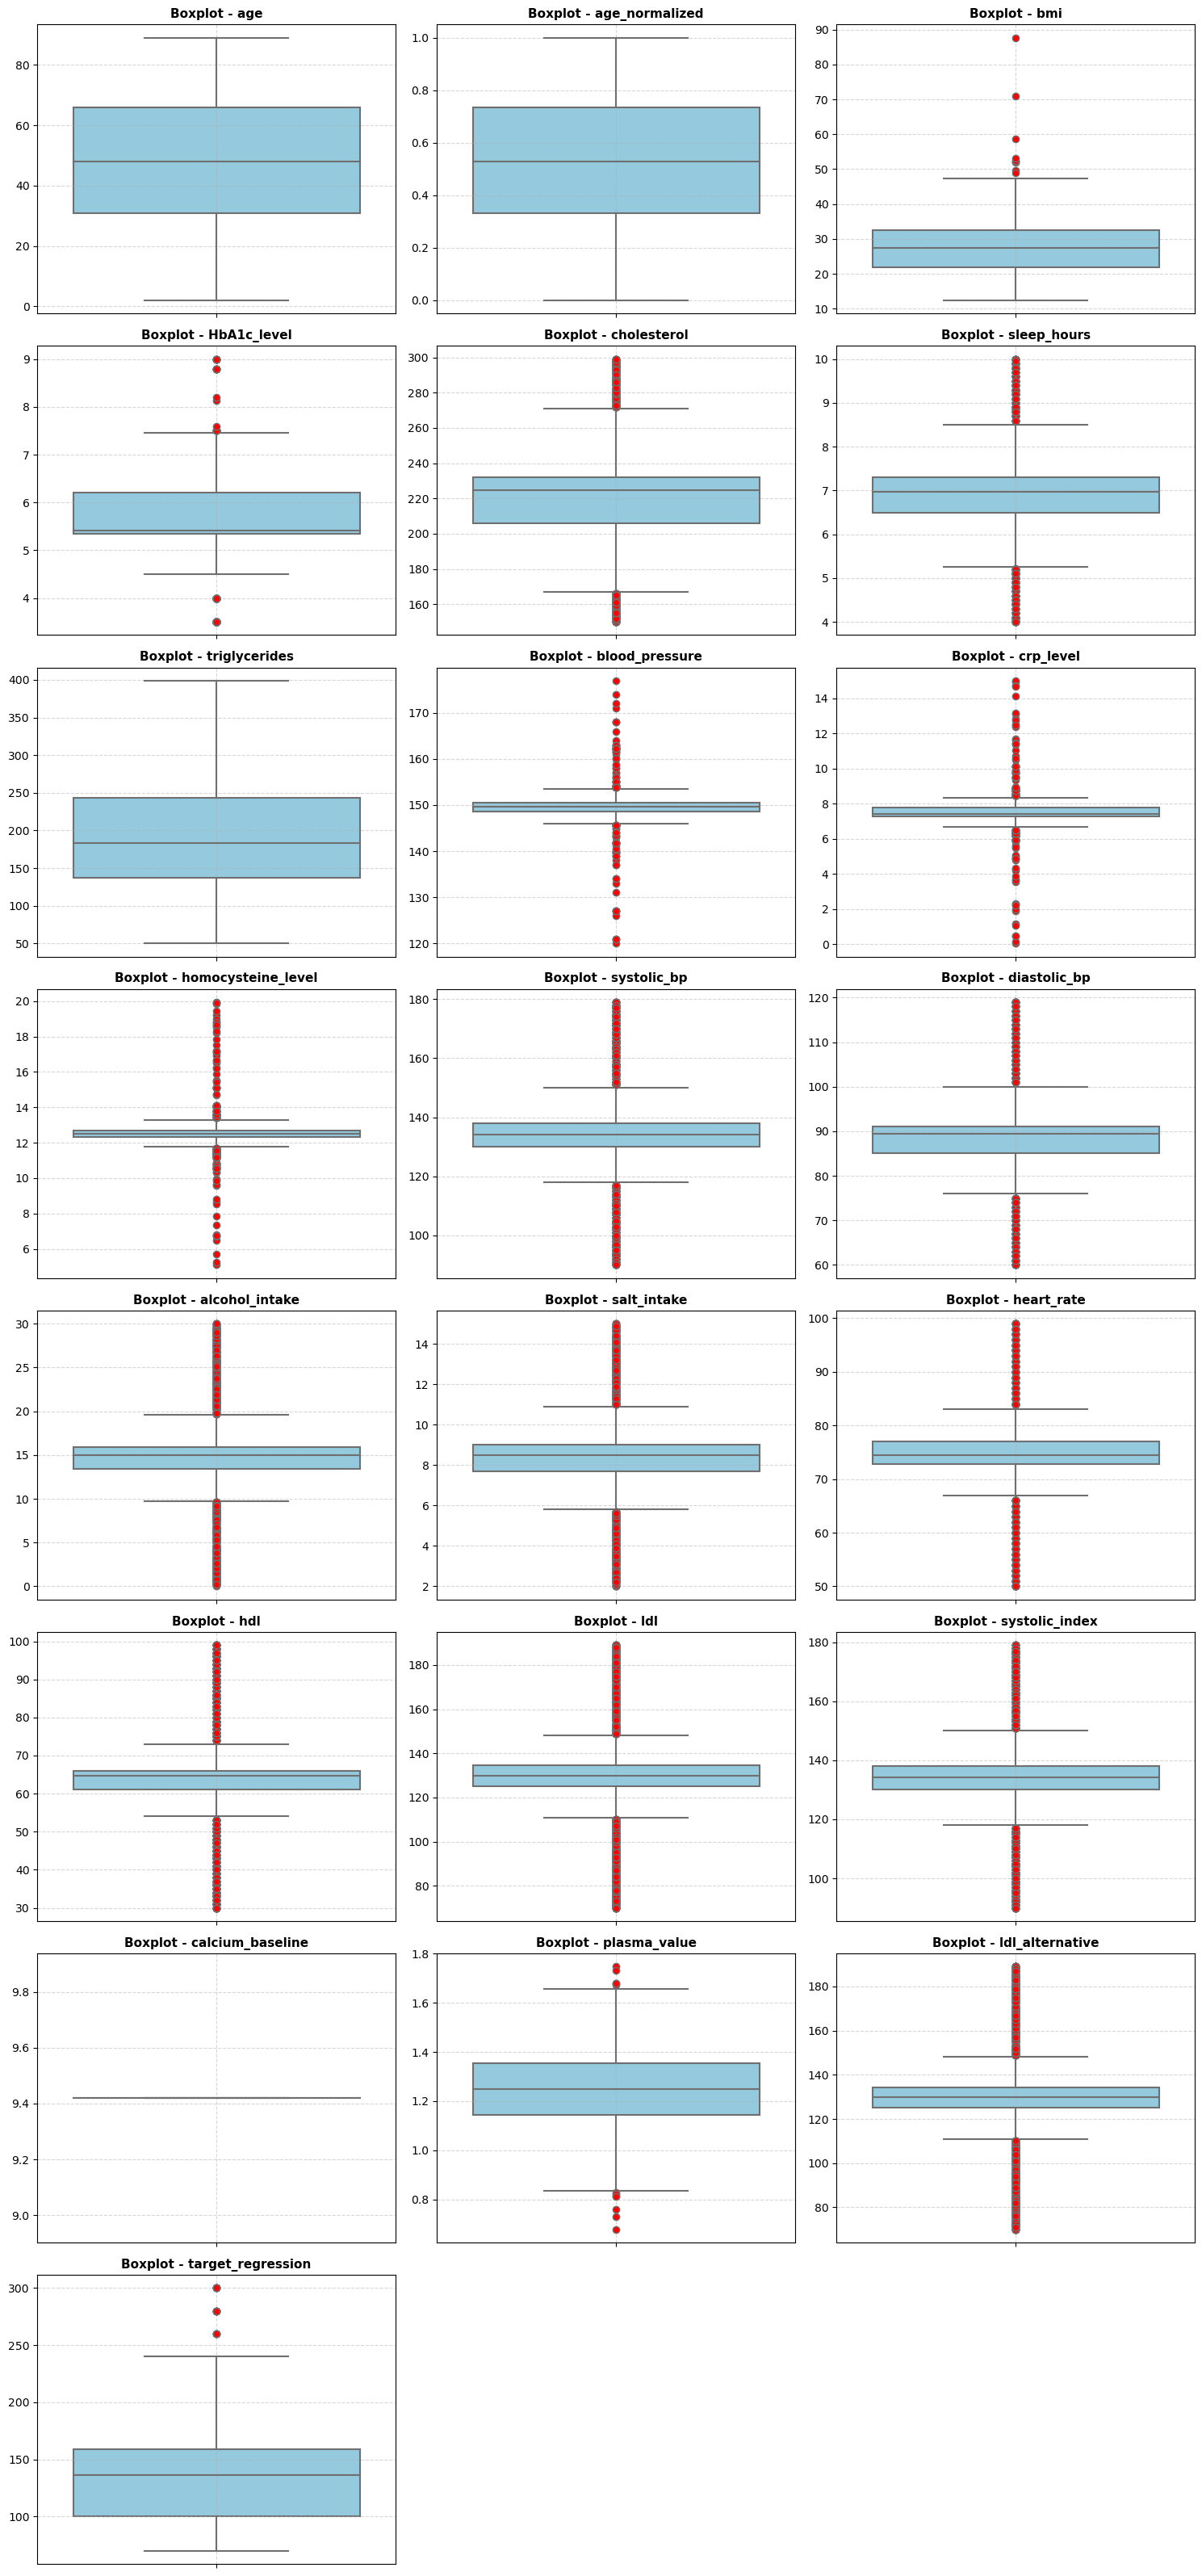

In [15]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 10.1 VISUAL OUTLIER ANALYSIS - BOXPLOTS GRID
# ============================================================

# Configuração da grelha de subplots
n_cols = 3  # Número de colunas no layout
n_vars = len(numeric_cols)
n_rows = math.ceil(n_vars / n_cols)

# Criação da figura
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4))

# Garantir que 'axes' seja uma lista/array 1D simples
if n_vars == 1:
    axes = [axes]
else:
    axes = axes.flatten()

# Plot de cada variável numérica
for i, col in enumerate(numeric_cols):
    sns.boxplot(
        y=df[col],
        ax=axes[i],
        color="skyblue",
        flierprops=dict(marker="o", markerfacecolor="red", markersize=6),
    )
    axes[i].set_title(f"Boxplot - {col}", fontsize=11, fontweight="bold")
    axes[i].set_ylabel("")
    axes[i].grid(True, linestyle="--", alpha=0.5)

# Ocultar eixos vazios/não utilizados no final da grelha
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

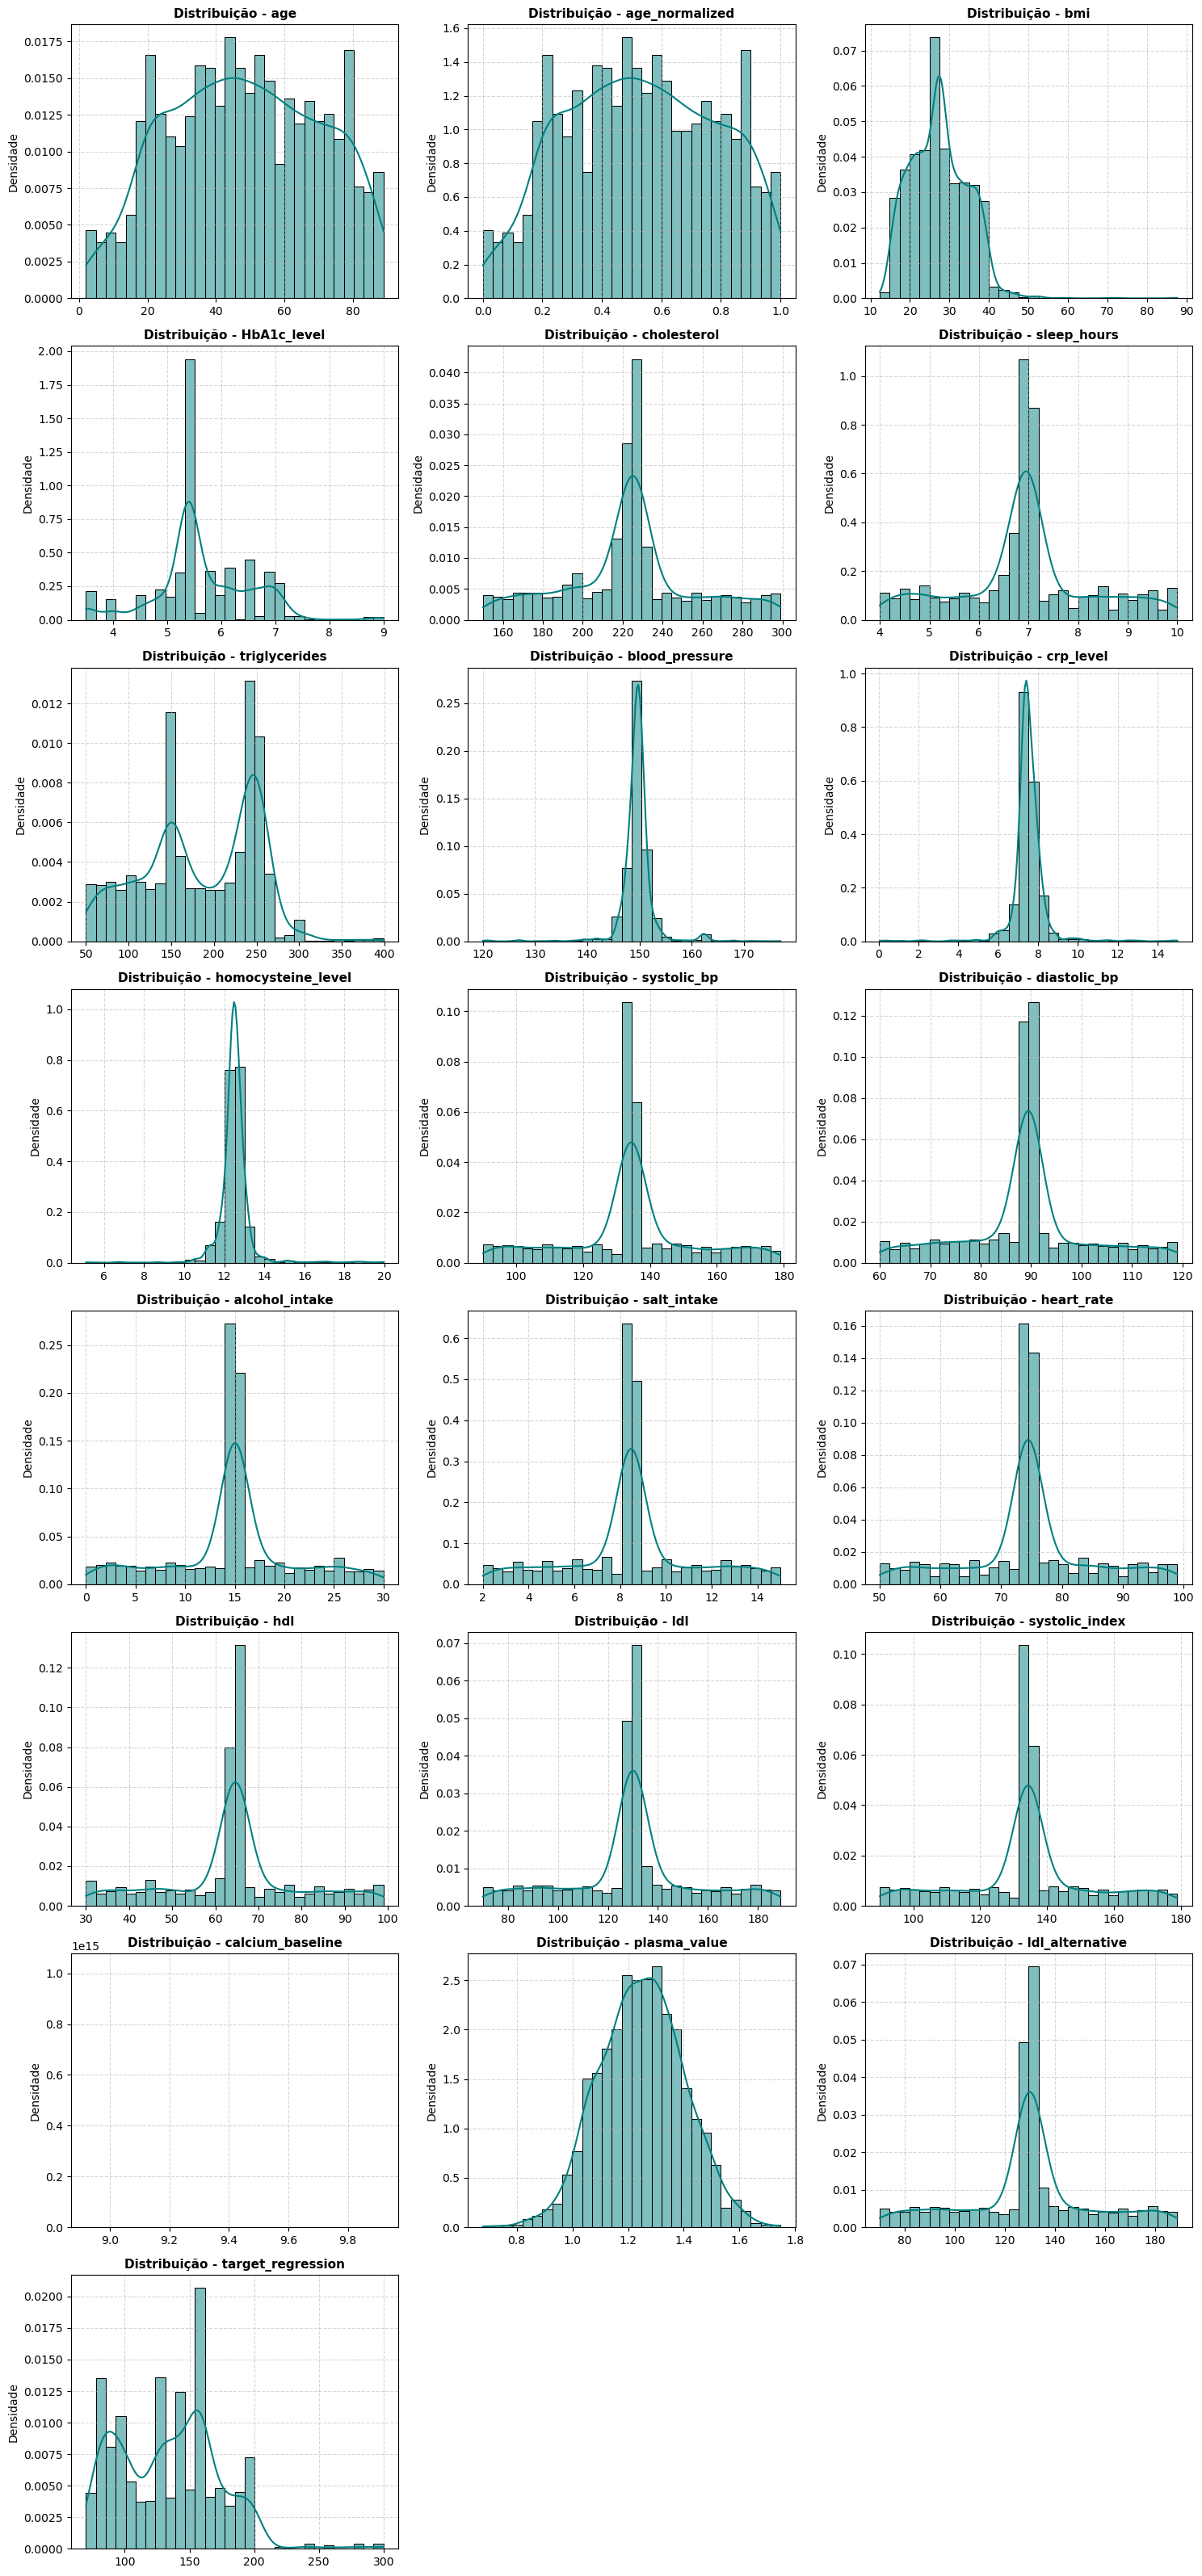

In [16]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 10.2 DISTRIBUTION ANALYSIS - HISTOGRAMS + KDE
# ============================================================

# Configuração da grelha de subplots
n_cols = 3  # Número de colunas
n_vars = len(numeric_cols)
n_rows = math.ceil(n_vars / n_cols)

# Criação da figura
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4))

# Ajuste do formato do eixos
if n_vars == 1:
    axes = [axes]
else:
    axes = axes.flatten()

# Plot dos histogramas com curva de densidade (KDE)
for i, col in enumerate(numeric_cols):
    sns.histplot(
        df[col],
        kde=True,
        ax=axes[i],
        color="teal",
        bins=30,
        stat="density",  # Permite comparar a curva KDE ajustada
    )
    axes[i].set_title(
        f"Distribuição - {col}", fontsize=11, fontweight="bold"
    )
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Densidade")
    axes[i].grid(True, linestyle="--", alpha=0.5)

# Ocultar eixos não utilizados
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


CORRELATION MATRIX
                         age  age_normalized       bmi  HbA1c_level  \
age                 1.000000        1.000000  0.096402     0.104491   
age_normalized      1.000000        1.000000  0.096402     0.104491   
bmi                 0.096402        0.096402  1.000000     0.041813   
HbA1c_level         0.104491        0.104491  0.041813     1.000000   
cholesterol         0.001560        0.001560  0.002352    -0.006744   
sleep_hours         0.028452        0.028452  0.036743    -0.012072   
triglycerides      -0.236845       -0.236845 -0.003540    -0.061578   
blood_pressure     -0.143100       -0.143101 -0.093575     0.073729   
crp_level           0.037514        0.037514 -0.096554    -0.014108   
homocysteine_level  0.050482        0.050482  0.105355    -0.001573   
systolic_bp         0.016034        0.016034 -0.017043    -0.014468   
diastolic_bp        0.010665        0.010665 -0.014707     0.002383   
alcohol_intake     -0.014907       -0.014907  0.002603   

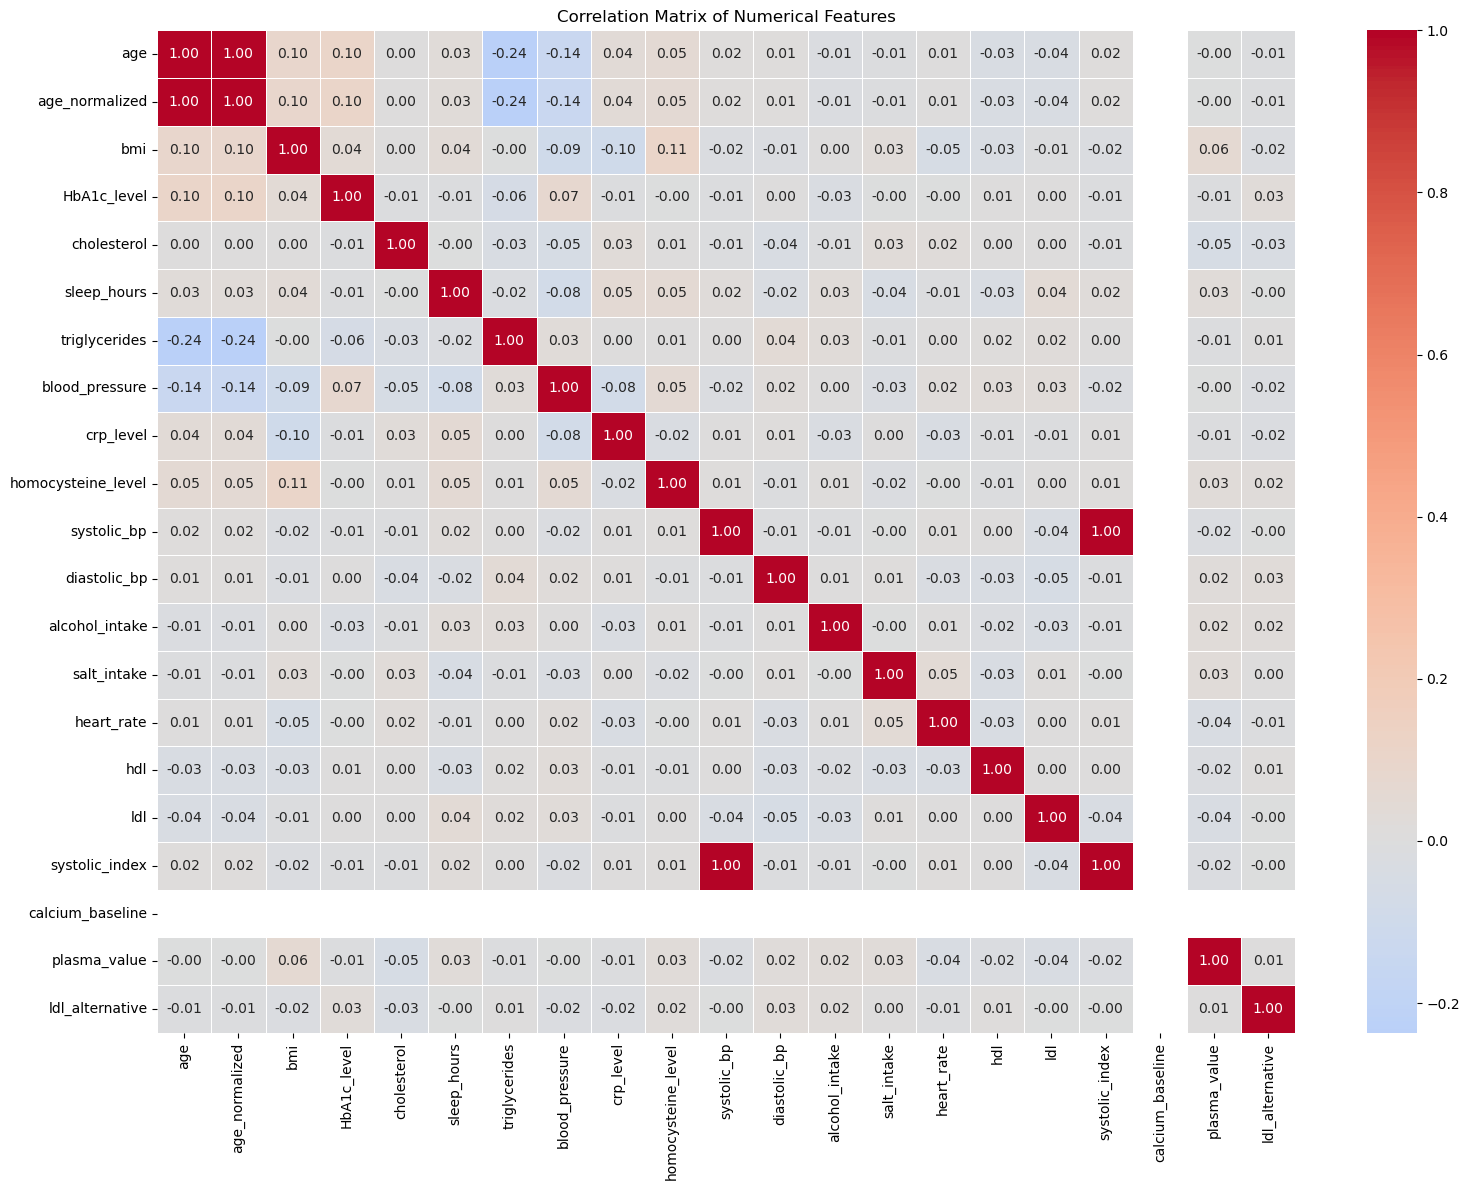

In [17]:
# ============================================================
# 11. CORRELATION MATRIX
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

print("\n" + "=" * 60)
print("CORRELATION MATRIX")
print("=" * 60)

# Remove target_regression
correlation = df[numeric_cols].drop(columns="target_regression").corr()

print(correlation)

# Heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

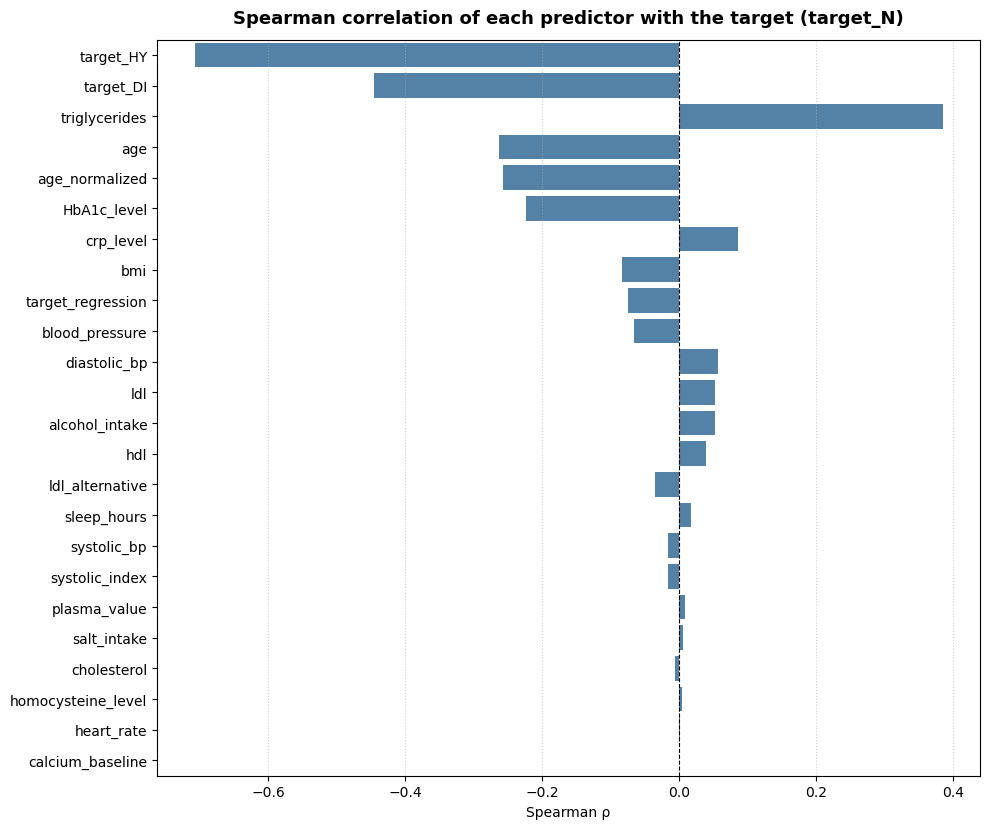

Correlation with the target, sorted by |ρ|:


,Spearman_rho,|rho|
target_HY,-0.7075,0.7075
target_DI,-0.4461,0.4461
triglycerides,0.3847,0.3847
age,-0.2637,0.2637
age_normalized,-0.2576,0.2576
HbA1c_level,-0.2239,0.2239
crp_level,0.0862,0.0862
bmi,-0.0831,0.0831
target_regression,-0.0746,0.0746
blood_pressure,-0.0660,0.0660


In [20]:
# Spearman correlation of each candidate predictor with the target (descriptive, full data)
sample_corr = df2.sample(min(len(df2), 100_000), random_state=42)
numeric_df = sample_corr.select_dtypes(include=["number"])

target_corr = (
    numeric_df.corr(method="spearman")[["target_N"]]
    .drop("target_N")
    .rename(columns={"target_N": "Spearman_rho"})
)
target_corr["|rho|"] = target_corr["Spearman_rho"].abs()
target_corr = target_corr.sort_values(by="|rho|", ascending=False)

plt.figure(figsize=(10, max(6, len(target_corr) * 0.35)))
#sns.barplot(x=target_corr["Spearman_rho"], y=target_corr.index, hue=target_corr.index,
#            palette="vlag", legend=False)
sns.barplot(
    data=target_corr.reset_index(names="Predictor"),
    x="Spearman_rho",
    y="Predictor",
    color="steelblue"
)
plt.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.title("Spearman correlation of each predictor with the target (target_N)",
          fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Spearman ρ")
plt.ylabel("")
plt.grid(axis="x", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

print("Correlation with the target, sorted by |ρ|:")
display(target_corr.round(4))

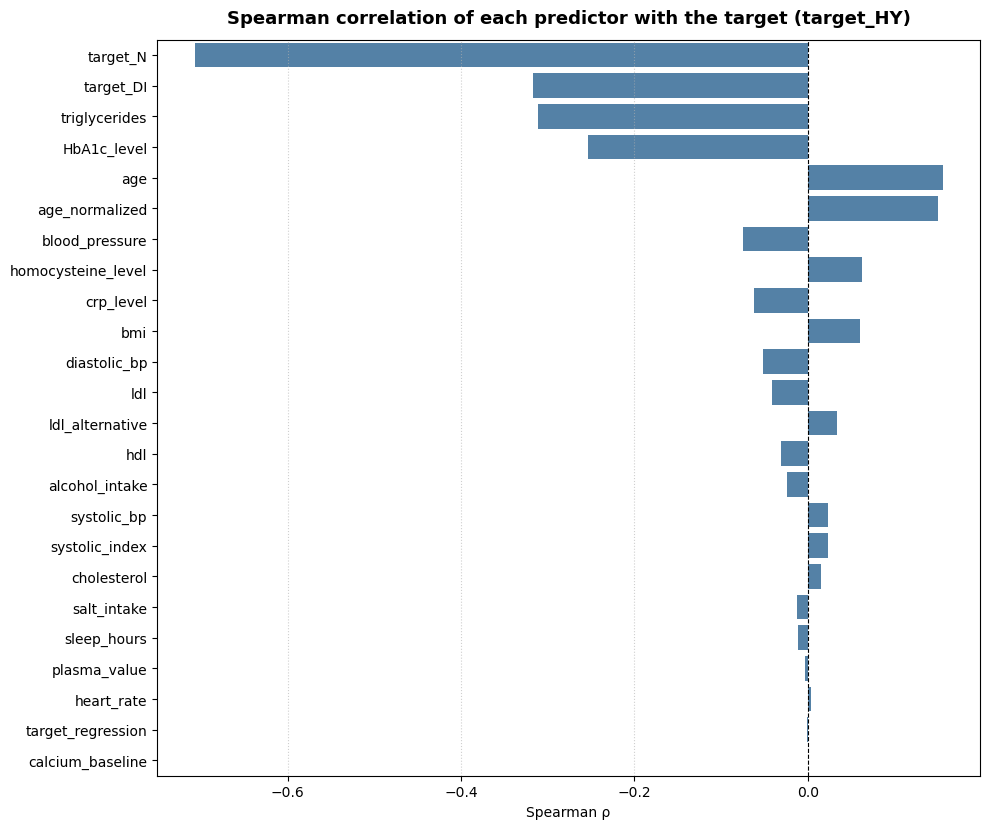

Correlation with the target, sorted by |ρ|:


,Spearman_rho,|rho|
target_N,-0.7075,0.7075
target_DI,-0.3169,0.3169
triglycerides,-0.3107,0.3107
HbA1c_level,-0.2532,0.2532
age,0.1554,0.1554
age_normalized,0.1505,0.1505
blood_pressure,-0.0750,0.0750
homocysteine_level,0.0628,0.0628
crp_level,-0.0619,0.0619
bmi,0.0597,0.0597


In [21]:
# Spearman correlation of each candidate predictor with the target (descriptive, full data)
sample_corr = df2.sample(min(len(df2), 100_000), random_state=42)
numeric_df = sample_corr.select_dtypes(include=["number"])

target_corr = (
    numeric_df.corr(method="spearman")[["target_HY"]]
    .drop("target_HY")
    .rename(columns={"target_HY": "Spearman_rho"})
)
target_corr["|rho|"] = target_corr["Spearman_rho"].abs()
target_corr = target_corr.sort_values(by="|rho|", ascending=False)

plt.figure(figsize=(10, max(6, len(target_corr) * 0.35)))
#sns.barplot(x=target_corr["Spearman_rho"], y=target_corr.index, hue=target_corr.index,
#            palette="vlag", legend=False)
sns.barplot(
    data=target_corr.reset_index(names="Predictor"),
    x="Spearman_rho",
    y="Predictor",
    color="steelblue"
)
plt.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.title("Spearman correlation of each predictor with the target (target_HY)",
          fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Spearman ρ")
plt.ylabel("")
plt.grid(axis="x", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

print("Correlation with the target, sorted by |ρ|:")
display(target_corr.round(4))

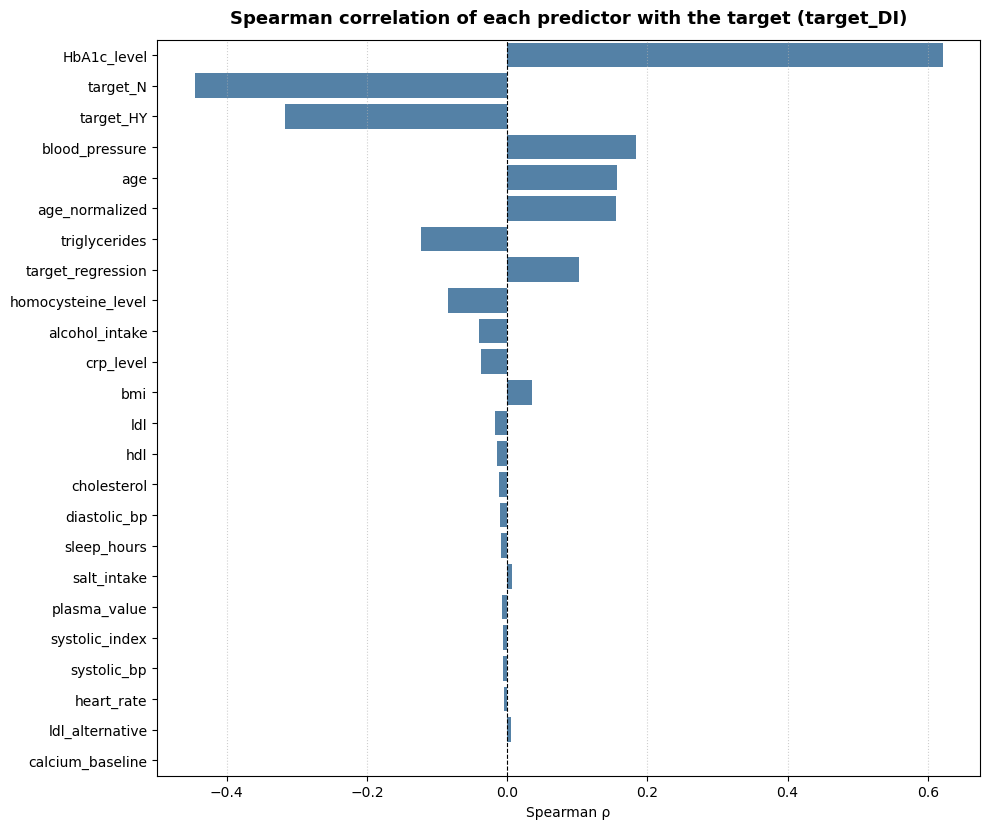

Correlation with the target, sorted by |ρ|:


,Spearman_rho,|rho|
HbA1c_level,0.6212,0.6212
target_N,-0.4461,0.4461
target_HY,-0.3169,0.3169
blood_pressure,0.1837,0.1837
age,0.1571,0.1571
age_normalized,0.1552,0.1552
triglycerides,-0.1228,0.1228
target_regression,0.1021,0.1021
homocysteine_level,-0.0848,0.0848
alcohol_intake,-0.0407,0.0407


In [23]:
# Spearman correlation of each candidate predictor with the target (descriptive, full data)
sample_corr = df2.sample(min(len(df2), 100_000), random_state=42)
numeric_df = sample_corr.select_dtypes(include=["number"])

target_corr = (
    numeric_df.corr(method="spearman")[["target_DI"]]
    .drop("target_DI")
    .rename(columns={"target_DI": "Spearman_rho"})
)
target_corr["|rho|"] = target_corr["Spearman_rho"].abs()
target_corr = target_corr.sort_values(by="|rho|", ascending=False)

plt.figure(figsize=(10, max(6, len(target_corr) * 0.35)))
#sns.barplot(x=target_corr["Spearman_rho"], y=target_corr.index, hue=target_corr.index,
#            palette="vlag", legend=False)
sns.barplot(
    data=target_corr.reset_index(names="Predictor"),
    x="Spearman_rho",
    y="Predictor",
    color="steelblue"
)
plt.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.title("Spearman correlation of each predictor with the target (target_DI)",
          fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Spearman ρ")
plt.ylabel("")
plt.grid(axis="x", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

print("Correlation with the target, sorted by |ρ|:")
display(target_corr.round(4))

In [24]:
# ============================================================
# 12. HIGHLY CORRELATED FEATURES
# ============================================================

print("\n" + "=" * 60)
print("HIGHLY CORRELATED FEATURES (|r| >= 0.80)")
print("=" * 60)

corr_pairs = (
    correlation
    .where(
        ~np.eye(
            correlation.shape[0],
            dtype=bool
        )
    )
    .stack()
    .reset_index()
)

corr_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

corr_pairs["Abs Correlation"] = (
    abs(corr_pairs["Correlation"])
)

# Remove duplicate pairs
corr_pairs["Pair"] = corr_pairs.apply(
    lambda row: tuple(
        sorted(
            [row["Feature 1"], row["Feature 2"]]
        )
    ),
    axis=1
)

high_corr = (
    corr_pairs[
        corr_pairs["Abs Correlation"] >= 0.80
    ]
    .drop_duplicates("Pair")
    .sort_values(
        "Abs Correlation",
        ascending=False
    )
    .drop(columns="Pair")
)

print(high_corr)


HIGHLY CORRELATED FEATURES (|r| >= 0.80)
       Feature 1       Feature 2  Correlation  Abs Correlation
206  systolic_bp  systolic_index          1.0              1.0
0            age  age_normalized          1.0              1.0


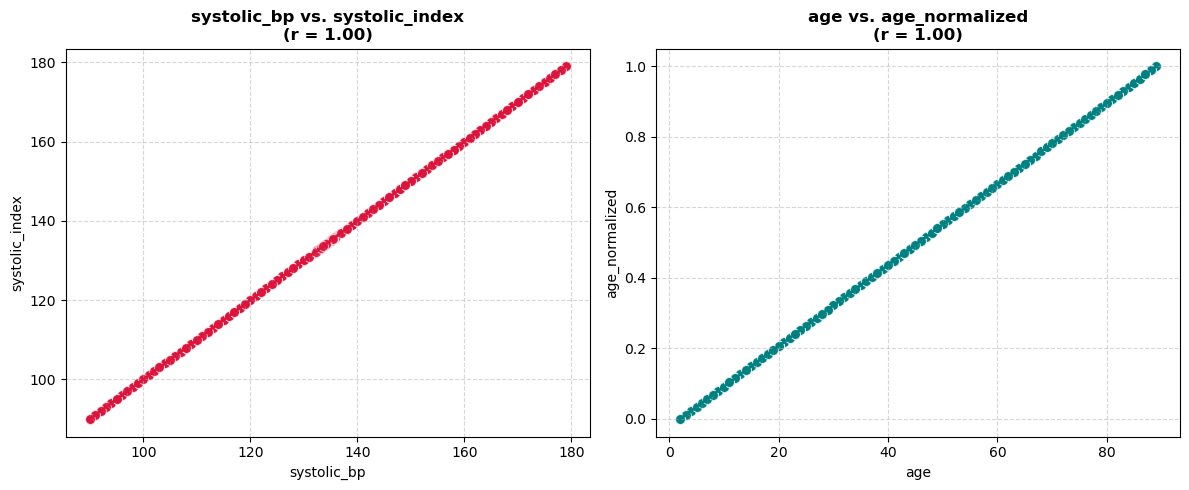

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# VISUALIZAÇÃO DE CORRELAÇÃO PERFEITA (r = 1.0)
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. Gráfico: systolic_bp vs systolic_index
sns.scatterplot(
    data=df,
    x="systolic_bp",
    y="systolic_index",
    ax=axes[0],
    color="crimson",
    s=50,
    alpha=0.8,
)
sns.regplot(
    data=df,
    x="systolic_bp",
    y="systolic_index",
    ax=axes[0],
    color="crimson",
    scatter=False,
    line_kws={"linewidth": 2},
)
axes[0].set_title(
    "systolic_bp vs. systolic_index\n(r = 1.00)", fontsize=12, fontweight="bold"
)
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Gráfico: age vs age_normalized
sns.scatterplot(
    data=df,
    x="age",
    y="age_normalized",
    ax=axes[1],
    color="teal",
    s=50,
    alpha=0.8,
)
sns.regplot(
    data=df,
    x="age",
    y="age_normalized",
    ax=axes[1],
    color="teal",
    scatter=False,
    line_kws={"linewidth": 2},
)
axes[1].set_title(
    "age vs. age_normalized\n(r = 1.00)", fontsize=12, fontweight="bold"
)
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [26]:
# ============================================================
# 13. TARGET_REGRESSION BY TARGET_CLASS
# ============================================================

print("\n" + "=" * 60)
print("TARGET_REGRESSION BY TARGET_CLASS")
print("=" * 60)

target_comparison = (
    df.groupby("target_class")["target_regression"]
    .describe()
)

print(target_comparison)


TARGET_REGRESSION BY TARGET_CLASS
              count        mean        std   min     25%    50%    75%    max
target_class                                                                 
DI            333.0  146.603604  49.499412  70.0  107.00  145.0  175.0  300.0
HY            669.0  133.136024  36.781696  70.0  101.00  133.0  163.0  200.0
N             998.0  130.239479  34.926485  71.0   96.25  130.0  158.0  200.0


Missing values: 0

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
target_regression,2000.0,133.933,38.745311,70.0,100.0,136.0,159.0,300.0


Skewness: 0.474
Unique values: 136


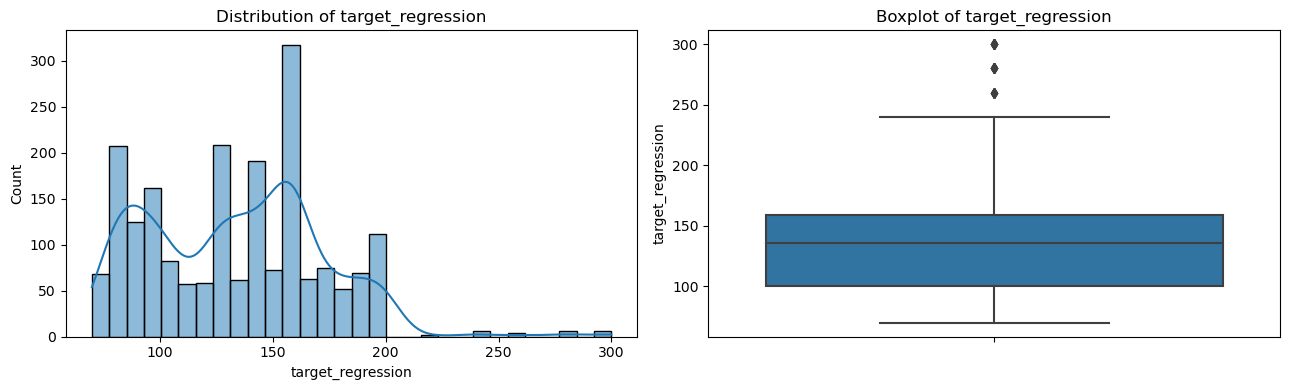

In [27]:
# ============================================================
# 14. TARGET_REGRESSION DISTRIBUTION AND OUTLIERS
# ============================================================

regression_target = "target_regression"

print("Missing values:", df[regression_target].isna().sum())
print("\nDescriptive statistics:")
display(df[regression_target].describe().to_frame().T)

print(f"Skewness: {df[regression_target].skew():.3f}")
print(f"Unique values: {df[regression_target].nunique()}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df[regression_target].dropna(), bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribution of target_regression")
axes[0].set_xlabel("target_regression")
axes[0].set_ylabel("Count")

sns.boxplot(y=df[regression_target], ax=axes[1])
axes[1].set_title("Boxplot of target_regression")
axes[1].set_ylabel("target_regression")

plt.tight_layout()
plt.show()

,count,mean,median,std,min,max
target_class,,,,,,
N,998,130.239479,130.0,34.926485,71.0,200.0
HY,669,133.136024,133.0,36.781696,70.0,200.0
DI,333,146.603604,145.0,49.499412,70.0,300.0


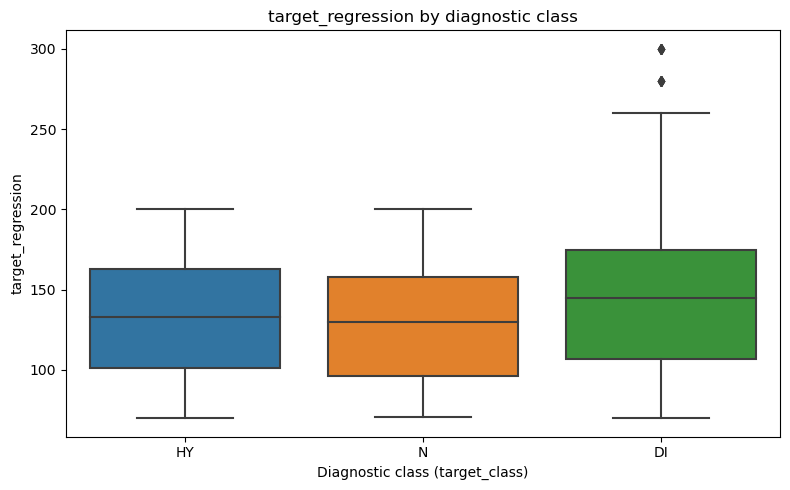

In [28]:
# ============================================================
# 15. TARGET_REGRESSION DISTRIBUTION AND OUTLIERS BY TARGET_CLASS
# ============================================================

regression_by_class = (
    df.groupby("target_class", observed=False)["target_regression"]
      .agg(["count", "mean", "median", "std", "min", "max"])
      .sort_values("median")
)
display(regression_by_class)

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="target_class", y="target_regression")
plt.title("target_regression by diagnostic class")
plt.xlabel("Diagnostic class (target_class)")
plt.ylabel("target_regression")
plt.tight_layout()
plt.show()

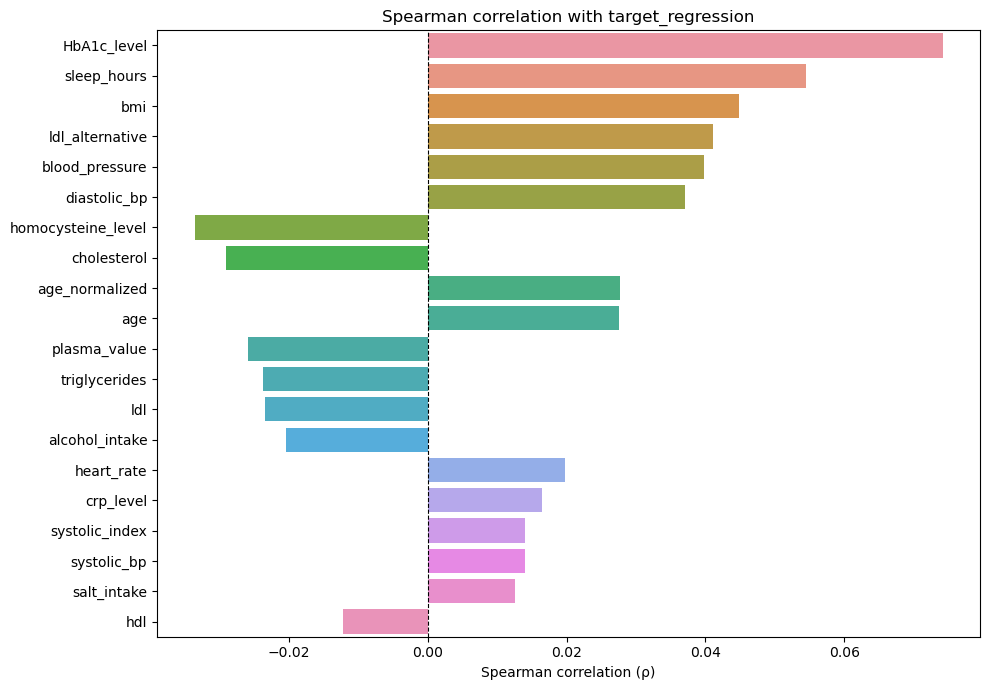

Correlation with target_regression, sorted by |ρ|:


,Spearman_rho,abs_rho
HbA1c_level,0.074,0.074
sleep_hours,0.055,0.055
bmi,0.045,0.045
ldl_alternative,0.041,0.041
blood_pressure,0.040,0.040
diastolic_bp,0.037,0.037
homocysteine_level,-0.034,0.034
cholesterol,-0.029,0.029
age_normalized,0.028,0.028
age,0.028,0.028


In [41]:
# ============================================================
# 16. TARGET_REGRESSION CORRELATION WITH OTHER NUMERIC VARIABLES
# ============================================================

numeric_predictors = df.select_dtypes(include="number").columns.drop(
    "target_regression", errors="ignore"
)
regression_corr = (
    df[list(numeric_predictors) + ["target_regression"]]
      .corr(method="spearman")["target_regression"]
      .drop("target_regression")
      .dropna()
      .to_frame("Spearman_rho")
)
regression_corr["abs_rho"] = regression_corr["Spearman_rho"].abs()
regression_corr = regression_corr.sort_values("abs_rho", ascending=False)

plt.figure(figsize=(10, max(6,len(regression_corr) * 0.35)))
sns.barplot(
    data=regression_corr.reset_index(names="feature"),
    x="Spearman_rho", y="feature"
)
plt.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.title("Spearman correlation with target_regression")
plt.xlabel("Spearman correlation (ρ)")
plt.ylabel("")
plt.tight_layout()
plt.show()

print("Correlation with target_regression, sorted by |ρ|:")
display(regression_corr.round(3))

In [30]:
# ============================================================
# 17. ENCODE CATEGORICAL VARIABLES
# ============================================================

target_columns = ["target_class", "target_regression"]
categorical_predictors = [
    col for col in df.select_dtypes(include=["object", "category"]).columns
    if col not in target_columns
]

print("Categorical predictor columns to encode:")
print(categorical_predictors)

df_encoded = pd.get_dummies(
    df,
    columns=categorical_predictors,
    drop_first=True,
    dtype=int
)

print("\nOriginal shape:", df.shape)
print("Encoded shape:", df_encoded.shape)
display(df_encoded.head())

Categorical predictor columns to encode:
['age_level', 'gender', 'bmi_level', 'smoking', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'sugar_consumption', 'education_level', 'employment_status']

Original shape: (2000, 35)
Encoded shape: (2000, 45)


,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,triglycerides,blood_pressure,crp_level,homocysteine_level,...,stress_level_Low,stress_level_Medium,low_hdl_cholesterol_Yes,high_ldl_cholesterol_Yes,sugar_consumption_Low,sugar_consumption_Medium,education_level_Secondary,education_level_Tertiary,employment_status_Retired,employment_status_Unemployed
0,44,0.482758,35.70,5.398540,250.000000,5.300000,235.000000,149.202128,7.252266,12.504625,...,0,0,0,0,0,1,0,0,0,0
1,49,0.540230,34.97,6.500000,224.684501,7.060728,149.460563,149.757035,7.294863,12.657538,...,0,0,0,1,1,0,1,0,0,1
2,4,0.022989,17.64,6.000000,228.130653,7.080402,156.115578,150.269231,7.824534,11.846610,...,1,0,0,1,0,1,0,1,0,0
3,40,0.436781,17.30,5.421429,299.000000,9.500000,150.000000,150.888889,9.762408,13.416151,...,1,0,0,1,1,0,0,0,0,0
4,27,0.287356,24.80,5.374373,277.000000,8.500000,187.000000,148.680000,7.389367,12.282381,...,1,0,1,1,0,1,0,1,0,0


In [39]:
# Create a copy to preserve the original dataframe
df_encoded = df.copy()

# Identificar as colunas alvo
target_columns = ["target_class", "target_regression"]

# 1. Ordinal encoding
ordinal_mappings = {
    "bmi_level": {
        "Underweight": 1,
        "Normal": 2,
        "Overweight": 3,
        "Obese": 4
    },
    "physical_activity": {
        "Low": 1,
        "Moderate": 2,
        "High": 3
    },
    "stress_level": {
        "Low": 1,
        "Medium": 2,
        "High": 3
    },
    "sugar_consumption": {
        "Low": 1,
        "Medium": 2,
        "High": 3
    }
}

for column, mapping in ordinal_mappings.items():
    df_encoded[column] = df_encoded[column].map(mapping)


# 2. Binary encoding
binary_mappings = {
    "gender": {
        "Male": 0,
        "Female": 1
    },
    "family_history": {
        "No": 0,
        "Yes": 1
    },
    "low_hdl_cholesterol": {
        "No": 0,
        "Yes": 1
    },
    "high_ldl_cholesterol": {
        "No": 0,
        "Yes": 1
    }
}

for column, mapping in binary_mappings.items():
    df_encoded[column] = df_encoded[column].map(mapping)


# 3. One-hot encoding
one_hot_categories = {
    "age_level": ["Young", "Middle", "Mature", "Senior"],
    "smoking": ["Never", "Former", "Current"],
    "education_level": ["Primary", "Secondary", "Tertiary"],
    "employment_status": ["Unemployed", "Employed", "Retired"]
}

for column, categories in one_hot_categories.items():
    df_encoded[column] = pd.Categorical(
        df_encoded[column],
        categories=categories
    )

df_encoded = pd.get_dummies(
    df_encoded,
    columns=list(one_hot_categories.keys()),
    dtype=int
)

# Check the result
display(df_encoded.head())
print("Encoded dataset shape:", df_encoded.shape)
display(df_encoded.dtypes.to_frame("Data type"))

# 6. Verificar o resultado
print("Original shape:", df.shape)
print("Encoded shape:", df_encoded.shape)

print("\nColunas finais:")
print(df_encoded.columns.tolist())

# Identificar as colunas que foram codificadas
encoded_columns = (
    list(ordinal_mappings.keys())
    + list(binary_mappings.keys())
    + [
        col
        for col in df_encoded.columns
        if any(
            col.startswith(f"{category}_")
            for category in one_hot_categories
        )
    ]
)

# Manter apenas colunas que existem no DataFrame
encoded_columns = [
    col for col in encoded_columns
    if col in df_encoded.columns
]


print("\nValores nulos nas colunas codificadas:")
print(df_encoded[encoded_columns].isna().sum())


,gender,bmi_level,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,triglycerides,physical_activity,...,age_level_Senior,smoking_Never,smoking_Former,smoking_Current,education_level_Primary,education_level_Secondary,education_level_Tertiary,employment_status_Unemployed,employment_status_Employed,employment_status_Retired
0,0,4,44,0.482758,35.70,5.398540,250.000000,5.300000,235.000000,3,...,0,1,0,0,1,0,0,0,1,0
1,0,4,49,0.540230,34.97,6.500000,224.684501,7.060728,149.460563,2,...,0,0,1,0,0,1,0,1,0,0
2,0,1,4,0.022989,17.64,6.000000,228.130653,7.080402,156.115578,2,...,0,1,0,0,0,0,1,0,1,0
3,0,1,40,0.436781,17.30,5.421429,299.000000,9.500000,150.000000,1,...,0,0,0,1,1,0,0,0,1,0
4,1,2,27,0.287356,24.80,5.374373,277.000000,8.500000,187.000000,3,...,0,0,0,1,0,0,1,0,1,0


Encoded dataset shape: (2000, 44)


,Data type
gender,int64
bmi_level,int64
age,int64
age_normalized,float64
bmi,float64
HbA1c_level,float64
cholesterol,float64
sleep_hours,float64
triglycerides,float64
physical_activity,int64


Original shape: (2000, 35)
Encoded shape: (2000, 44)

Colunas finais:
['gender', 'bmi_level', 'age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'blood_pressure', 'sugar_consumption', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'systolic_index', 'calcium_baseline', 'plasma_value', 'ldl_alternative', 'target_regression', 'target_class', 'age_level_Young', 'age_level_Middle', 'age_level_Mature', 'age_level_Senior', 'smoking_Never', 'smoking_Former', 'smoking_Current', 'education_level_Primary', 'education_level_Secondary', 'education_level_Tertiary', 'employment_status_Unemployed', 'employment_status_Employed', 'employment_status_Retired']

Valores nulos nas colunas codificadas:
bmi_level                       0
physical_activity               0
stress_level      

## Complementos à Análise Exploratória (EDA)

As secções anteriores cobrem estatísticas descritivas, outliers, distribuições e correlações numéricas. Esta parte completa o enunciado com:

1. **Análise univariada das variáveis categóricas** (as numéricas já têm histogramas/boxplots).
2. **Identificação de variáveis constantes, redundantes ou pouco informativas**, com evidência numérica.
3. **Análise bivariada** entre as *features* e os dois alvos (`target_class` e `target_regression`), com testes de associação e correção para testes múltiplos.

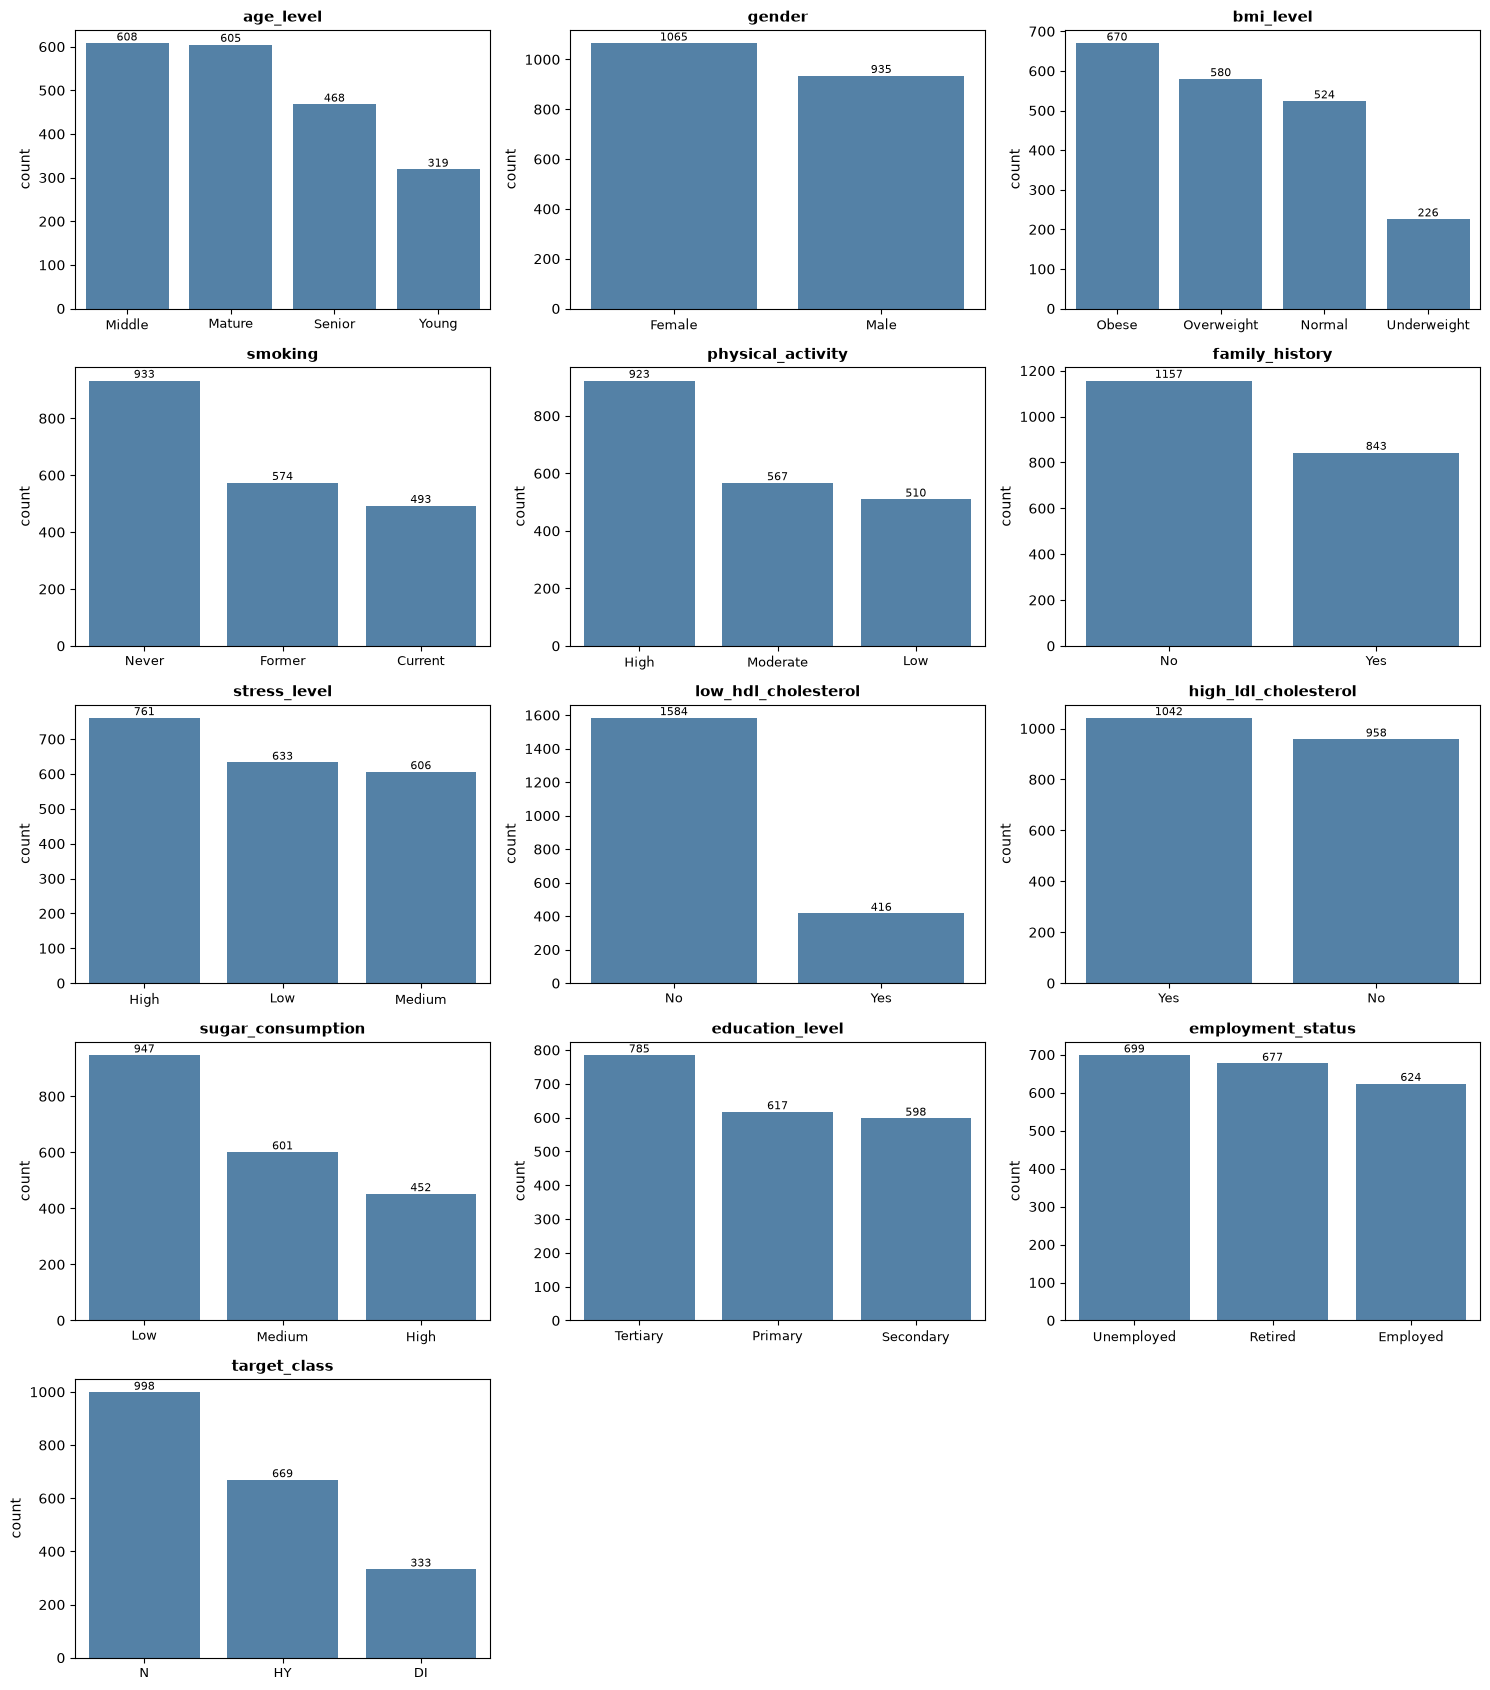

In [29]:
# ============================================================
# 18. UNIVARIATE ANALYSIS - CATEGORICAL VARIABLES
# ============================================================
import math
from scipy import stats

categorical_all = df.select_dtypes(exclude="number").columns.tolist()  # inclui target_class

n_cols = 3
n_rows = math.ceil(len(categorical_all) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 3.4))
axes = axes.flatten()

for ax, col in zip(axes, categorical_all):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, color="steelblue", ax=ax)
    for container in ax.containers:
        ax.bar_label(container, fontsize=8)
    ax.set_title(col, fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.tick_params(axis="x", labelsize=9)

for ax in axes[len(categorical_all):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

### Variáveis constantes, redundantes ou pouco informativas

Para cada suspeita, a evidência é calculada em vez de assumida: constantes (`nunique`), cópias exatas ou transformações lineares (correlação / igualdade), variáveis categóricas que são apenas uma discretização de uma contínua (intervalos sem sobreposição) e *flags* derivadas de limiares.

In [30]:
# ============================================================
# 19. REDUNDANT / UNINFORMATIVE FEATURES - EVIDENCE
# ============================================================

def non_overlapping_bins(numeric, categorical):
    """True se cada categoria ocupa um intervalo da variável contínua sem sobreposição."""
    ranges = df.groupby(categorical)[numeric].agg(["min", "max"]).sort_values("min")
    return bool((ranges["max"].values[:-1] < ranges["min"].values[1:]).all())


def range_overlap(numeric, categorical):
    ranges = df.groupby(categorical)[numeric].agg(["min", "max"]).sort_values("min")
    return float(ranges["max"].iloc[0] - ranges["min"].iloc[1])


redundancy = pd.DataFrame(
    [
        ("calcium_baseline", "-", f"{df['calcium_baseline'].nunique()} valor único ({df['calcium_baseline'].iloc[0]})", "Remover (constante)"),
        ("age_normalized", "age", f"|r| = {abs(df['age'].corr(df['age_normalized'])):.6f} (min-max de age)", "Remover (transformação linear)"),
        ("systolic_index", "systolic_bp", f"valores idênticos em todas as linhas: {bool((df['systolic_bp'] == df['systolic_index']).all())}", "Remover (cópia)"),
        ("ldl_alternative", "ldl", f"mesmo multiconjunto de valores: {sorted(df['ldl']) == sorted(df['ldl_alternative'])}; "
                                  f"linhas iguais: {(df['ldl'] == df['ldl_alternative']).mean():.1%}; "
                                  f"r = {df['ldl'].corr(df['ldl_alternative']):.3f}", "Remover (permutação de ldl, sem informação nova)"),
        ("age_level", "age", f"intervalos sem sobreposição: {non_overlapping_bins('age', 'age_level')}", "Remover (discretização de age)"),
        ("bmi_level", "bmi", f"intervalos sem sobreposição: {non_overlapping_bins('bmi', 'bmi_level')}", "Remover (discretização de bmi)"),
        ("low_hdl_cholesterol", "hdl", f"categorias sobrepõem-se em {range_overlap('hdl', 'low_hdl_cholesterol'):.1f} unidades", "Manter com cautela (flag ruidosa)"),
        ("high_ldl_cholesterol", "ldl", f"categorias sobrepõem-se em {range_overlap('ldl', 'high_ldl_cholesterol'):.1f} unidades", "Manter com cautela (flag ruidosa)"),
    ],
    columns=["Feature", "Relacionada com", "Evidência", "Decisão"],
)
display(redundancy)

# Variáveis numéricas com variância muito baixa face à escala (sinal de pouco poder discriminativo)
num_features = df.select_dtypes(include="number").columns.drop(["target_regression"])
cv_table = (df[num_features].std() / df[num_features].mean().abs()).rename("Coef. variação").sort_values()
print("Coeficiente de variação (std/|média|) - valores muito baixos indicam variável quase invariante:")
display(cv_table.round(4).head(5).to_frame())

,Feature,Relacionada com,Evidência,Decisão
0,calcium_baseline,-,1 valor único (9.42),Remover (constante)
1,age_normalized,age,|r| = 1.000000 (min-max de age),Remover (transformação linear)
2,systolic_index,systolic_bp,valores idênticos em todas as linhas: True,Remover (cópia)
3,ldl_alternative,ldl,mesmo multiconjunto de valores: True; linhas i...,"Remover (permutação de ldl, sem informação nova)"
4,age_level,age,intervalos sem sobreposição: True,Remover (discretização de age)
5,bmi_level,bmi,intervalos sem sobreposição: True,Remover (discretização de bmi)
6,low_hdl_cholesterol,hdl,categorias sobrepõem-se em 27.3 unidades,Manter com cautela (flag ruidosa)
7,high_ldl_cholesterol,ldl,categorias sobrepõem-se em 5.9 unidades,Manter com cautela (flag ruidosa)


Coeficiente de variação (std/|média|) - valores muito baixos indicam variável quase invariante:


,Coef. variação
calcium_baseline,0.0000
blood_pressure,0.0229
homocysteine_level,0.0748
plasma_value,0.1209
crp_level,0.1215


In [31]:
# ============================================================
# 20. BIVARIATE ANALYSIS - NUMERICAL FEATURES vs TARGETS
# ============================================================
# Para target_class (3 grupos): Kruskal-Wallis (não assume normalidade) + eta^2 (H-based).
# Para target_regression: correlação de Pearson e Spearman com p-values.

num_feats = [c for c in df.select_dtypes(include="number").columns
             if c not in ("target_regression", "calcium_baseline")]
classes = sorted(df["target_class"].unique())
n_total = len(df)

rows = []
for col in num_feats:
    groups = [df.loc[df["target_class"] == k, col] for k in classes]
    H, p_kw = stats.kruskal(*groups)
    eta2 = (H - len(classes) + 1) / (n_total - len(classes))
    r_p, p_p = stats.pearsonr(df[col], df["target_regression"])
    r_s, p_s = stats.spearmanr(df[col], df["target_regression"])
    rows.append({
        "Feature": col,
        "KW_p (vs class)": p_kw, "eta2 (vs class)": max(eta2, 0),
        "Pearson r (vs reg)": r_p, "Pearson_p": p_p,
        "Spearman rho (vs reg)": r_s, "Spearman_p": p_s,
    })

num_assoc = pd.DataFrame(rows).set_index("Feature")
n_tests = len(num_assoc)
for pc in ["KW_p (vs class)", "Pearson_p", "Spearman_p"]:
    num_assoc[pc + "_bonf"] = (num_assoc[pc] * n_tests).clip(upper=1)

display(num_assoc.sort_values("KW_p (vs class)").round(4))
print(f"Bonferroni com {n_tests} testes por alvo: significativo se p_bonf < 0.05.")

,KW_p (vs class),eta2 (vs class),Pearson r (vs reg),Pearson_p,Spearman rho (vs reg),Spearman_p,KW_p (vs class)_bonf,Pearson_p_bonf,Spearman_p_bonf
Feature,,,,,,,,,
HbA1c_level,0.0000,0.3888,0.1123,0.0000,0.0742,0.0009,0.0000,0.0000,0.0180
triglycerides,0.0000,0.1501,-0.0128,0.5664,-0.0238,0.2877,0.0000,1.0000,1.0000
age,0.0000,0.0705,0.0305,0.1721,0.0276,0.2176,0.0000,1.0000,1.0000
age_normalized,0.0000,0.0675,0.0305,0.1721,0.0277,0.2151,0.0000,1.0000,1.0000
blood_pressure,0.0000,0.0331,0.0300,0.1793,0.0398,0.0753,0.0000,1.0000,1.0000
homocysteine_level,0.0002,0.0076,-0.0148,0.5072,-0.0336,0.1327,0.0036,1.0000,1.0000
crp_level,0.0006,0.0064,-0.0127,0.5704,0.0165,0.4609,0.0118,1.0000,1.0000
bmi,0.0010,0.0059,0.0467,0.0366,0.0449,0.0447,0.0202,0.7328,0.8949
diastolic_bp,0.0294,0.0025,0.0344,0.1246,0.0371,0.0973,0.5877,1.0000,1.0000


Bonferroni com 20 testes por alvo: significativo se p_bonf < 0.05.


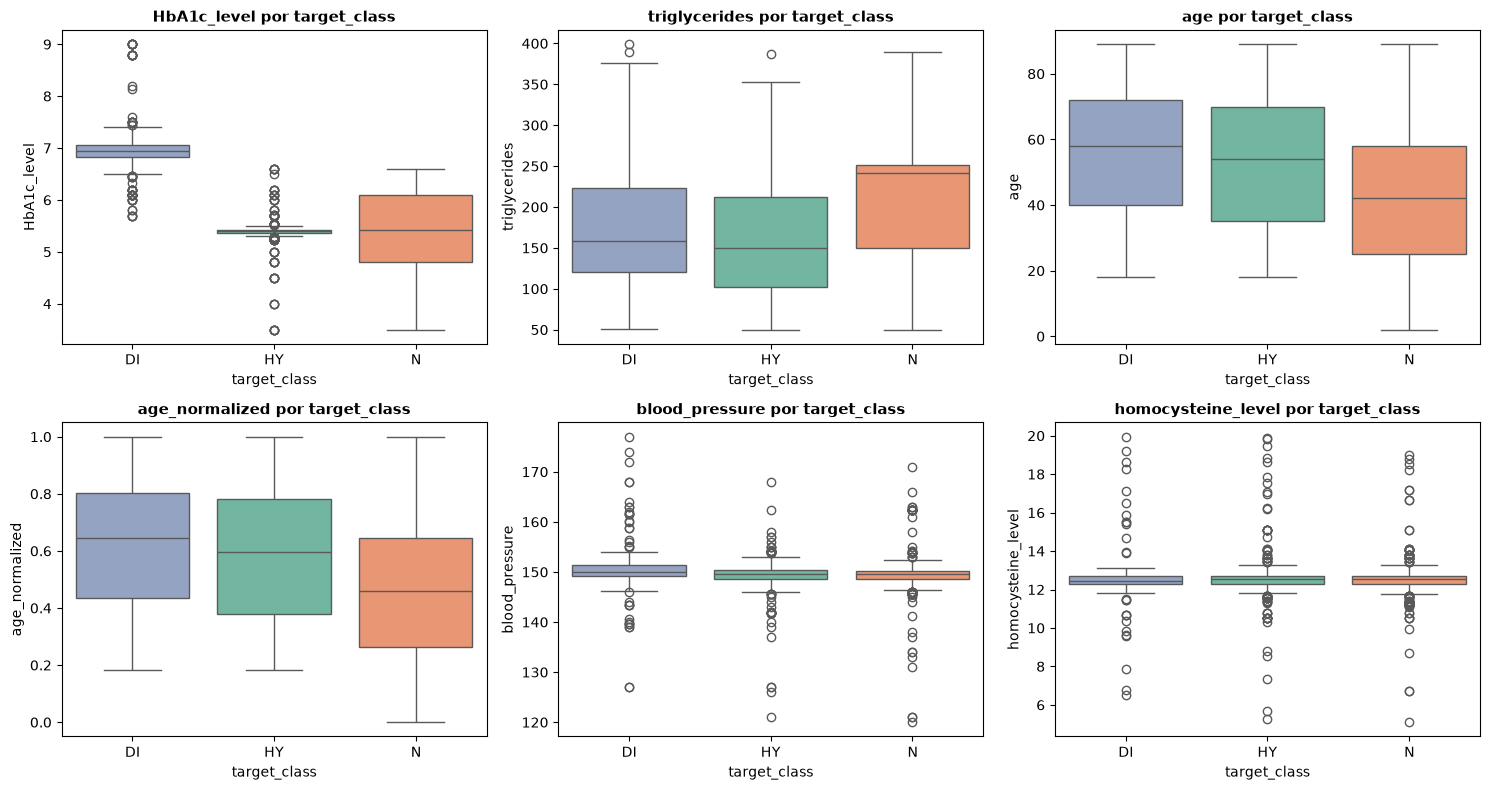

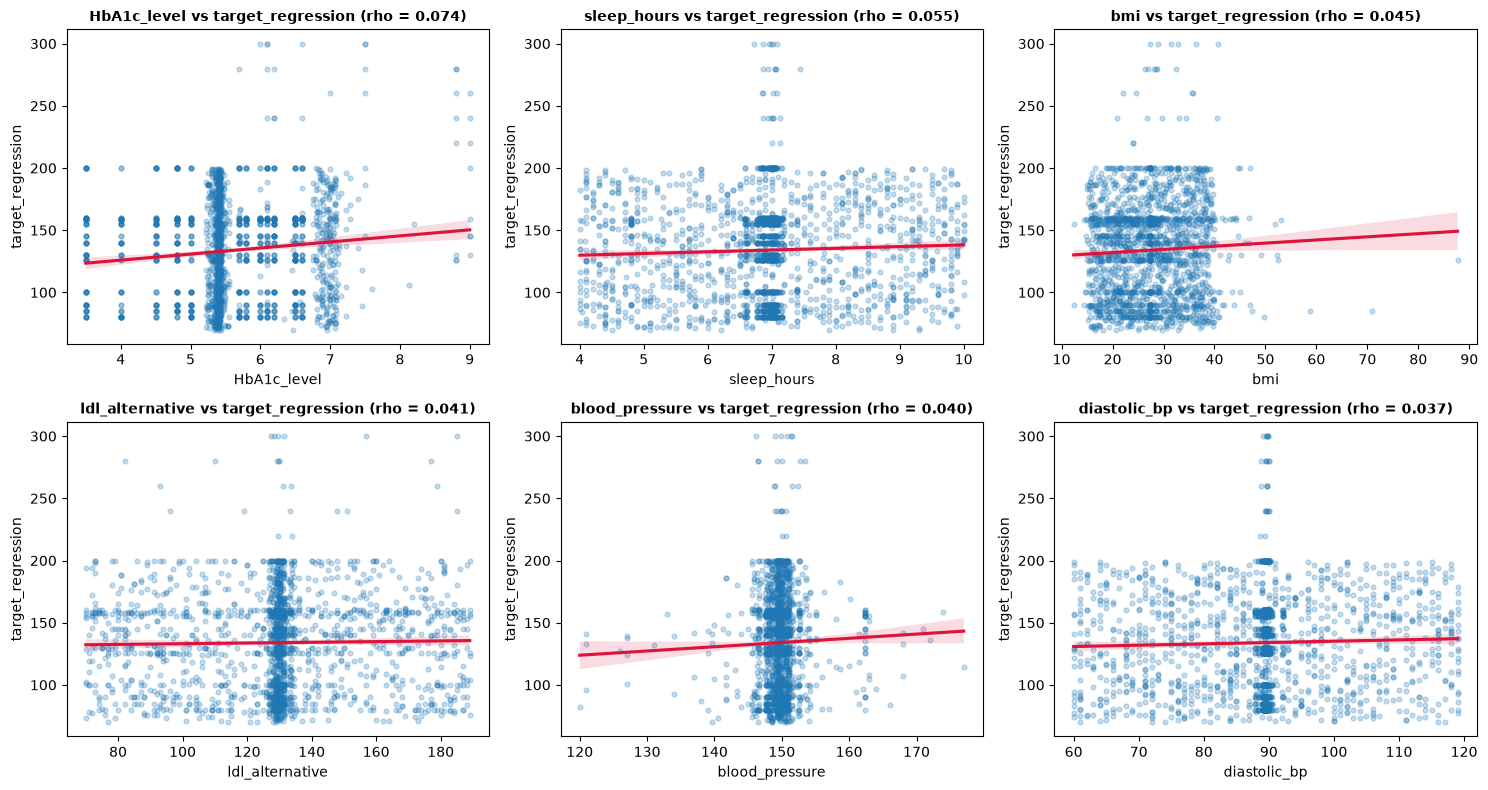

In [32]:
# Boxplots das features numéricas mais associadas a target_class e correlação com o alvo de regressão
top_class = num_assoc.sort_values("KW_p (vs class)").index[:6]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), top_class):
    sns.boxplot(data=df, x="target_class", y=col, order=classes, hue="target_class",
                palette="Set2", legend=False, ax=ax)
    ax.set_title(f"{col} por target_class", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

top_reg = num_assoc["Spearman rho (vs reg)"].abs().sort_values(ascending=False).index[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), top_reg):
    sns.regplot(data=df, x=col, y="target_regression", scatter_kws={"alpha": 0.25, "s": 12},
                line_kws={"color": "crimson"}, ax=ax)
    rho = num_assoc.loc[col, "Spearman rho (vs reg)"]
    ax.set_title(f"{col} vs target_regression (rho = {rho:.3f})", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

,chi2_p (vs class),Cramer V (vs class),KW_p (vs reg),eta2 (vs reg),chi2_p (vs class)_bonf,KW_p (vs reg)_bonf
Feature,,,,,,
smoking,0.0000,0.2002,0.9492,0.0000,0.0000,1.0000
age_level,0.0000,0.1883,0.0829,0.0018,0.0000,0.9951
physical_activity,0.0000,0.1541,0.4567,0.0000,0.0000,1.0000
bmi_level,0.0000,0.1313,0.2754,0.0004,0.0000,1.0000
family_history,0.0000,0.1211,0.5930,0.0000,0.0000,1.0000
sugar_consumption,0.0000,0.0853,0.2938,0.0002,0.0001,1.0000
education_level,0.0000,0.0809,0.3355,0.0001,0.0004,1.0000
stress_level,0.0009,0.0685,0.1671,0.0008,0.0106,1.0000
low_hdl_cholesterol,0.0029,0.0764,0.3180,0.0000,0.0352,1.0000


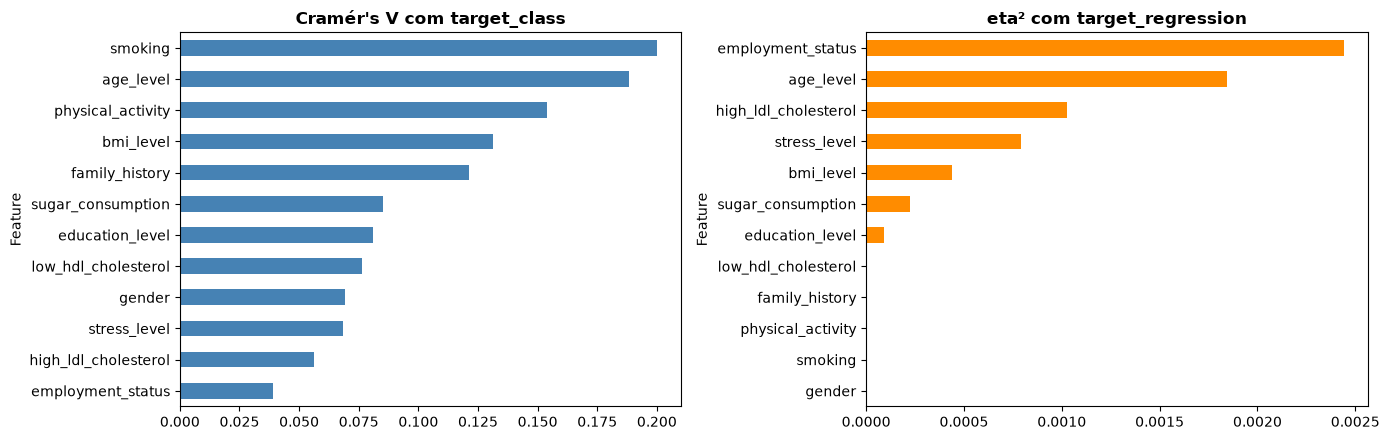

In [33]:
# ============================================================
# 21. BIVARIATE ANALYSIS - CATEGORICAL FEATURES vs TARGETS
# ============================================================
# target_class: qui-quadrado + V de Cramér. target_regression: Kruskal-Wallis + eta^2.

def cramers_v(table):
    chi2, p, dof, _ = stats.chi2_contingency(table)
    n = table.to_numpy().sum()
    k = min(table.shape) - 1
    return chi2, p, np.sqrt(chi2 / (n * k))

cat_feats = [c for c in categorical_all if c != "target_class"]
rows = []
for col in cat_feats:
    _, p_chi, v = cramers_v(pd.crosstab(df[col], df["target_class"]))
    groups = [g["target_regression"].values for _, g in df.groupby(col)]
    H, p_kw = stats.kruskal(*groups)
    eta2 = max((H - len(groups) + 1) / (n_total - len(groups)), 0)
    rows.append({"Feature": col, "chi2_p (vs class)": p_chi, "Cramer V (vs class)": v,
                 "KW_p (vs reg)": p_kw, "eta2 (vs reg)": eta2})

cat_assoc = pd.DataFrame(rows).set_index("Feature")
n_tests = len(cat_assoc)
for pc in ["chi2_p (vs class)", "KW_p (vs reg)"]:
    cat_assoc[pc + "_bonf"] = (cat_assoc[pc] * n_tests).clip(upper=1)

display(cat_assoc.sort_values("chi2_p (vs class)").round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
cat_assoc["Cramer V (vs class)"].sort_values().plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("Cramér's V com target_class", fontweight="bold")
cat_assoc["eta2 (vs reg)"].sort_values().plot.barh(ax=axes[1], color="darkorange")
axes[1].set_title("eta² com target_regression", fontweight="bold")
plt.tight_layout()
plt.show()

In [34]:
# target_regression por classe: ANOVA/Kruskal e quanto da variância é explicada pela classe
groups = [df.loc[df["target_class"] == k, "target_regression"] for k in classes]
H, p_kw = stats.kruskal(*groups)
ss_between = sum(len(g) * (g.mean() - df["target_regression"].mean()) ** 2 for g in groups)
ss_total = ((df["target_regression"] - df["target_regression"].mean()) ** 2).sum()

print(f"Kruskal-Wallis target_regression ~ target_class: H = {H:.2f}, p = {p_kw:.2e}")
print(f"Variância de target_regression explicada por target_class (eta^2): {ss_between / ss_total:.3%}")
print("\nValores de target_regression acima de 200 (possíveis outliers):")
display(df.loc[df["target_regression"] > 200, "target_class"].value_counts().to_frame("n"))

Kruskal-Wallis target_regression ~ target_class: H = 22.96, p = 1.03e-05
Variância de target_regression explicada por target_class (eta^2): 2.249%

Valores de target_regression acima de 200 (possíveis outliers):


,n
target_class,
DI,24


## Conclusões

### Análise exploratória
- **Dimensão e qualidade**: 2000 registos, sem valores em falta nem duplicados. Alvo de classificação desbalanceado (N 49.9%, HY 33.5%, DI 16.7%).
- **Variáveis a remover/ignorar**: `calcium_baseline` (constante), `age_normalized` (transformação linear de `age`), `systolic_index` (cópia de `systolic_bp`), `ldl_alternative` (permutação dos valores de `ldl`, sem informação nova) e `age_level`/`bmi_level` (discretizações exatas de `age`/`bmi`). `low_hdl_cholesterol` e `high_ldl_cholesterol` são *flags* ruidosas (categorias sobrepostas).
- **`target_class`**: `HbA1c_level` é de longe a variável mais discriminativa (eta² ≈ 0.39), seguida de `triglycerides` e `age`; entre as categóricas destacam-se `smoking`, `age_level` e `physical_activity` (V de Cramér 0.15–0.20).
- **`target_regression`**: praticamente **não está linearmente associado** a nenhuma *feature*. A mais forte é `HbA1c_level` (r = 0.11); `bmi` e `sleep_hours` têm |r| < 0.05. Nenhuma categórica é significativa após Bonferroni e `target_class` explica apenas ≈ 2.2% da variância. Os 24 valores acima de 200 pertencem todos à classe DI.
